# Entrega final — Auditoría de una STN para el pronóstico horario de PM2,5 en Fontibón

Universidad Externado de Colombia. Proyecto Integrador de Deep Learning.
Estudiante: Johan Velandia. Profesor: Wilmer Darío Pineda Ríos. Entrega final (Fase 3), 2026.

Este notebook cierra el proyecto: consolida el modelo final, presenta su evaluación única sobre el conjunto
de prueba de Fontibón, audita qué aprendió la red, caracteriza sus fallas y emite el dictamen sobre la
profundidad. **No entrena ni vuelve a evaluar nada**: lee los resultados que produjeron los scripts de la
Fase 3, en este orden:

1. `scripts/freeze_f3_protocol.py`: congela el protocolo antes de tocar test.
2. `scripts/run_f3_test_evaluation.py`: evaluación única sobre test; se niega a ejecutarse dos veces.
3. `scripts/run_f3_explainability.py`: atención, gradientes integrados, casos sintéticos y ablaciones.
4. `scripts/run_f3_failure_analysis.py`: fallas por subgrupo, calibración y entradas fuera de dominio.

In [1]:
import json
import sys
from pathlib import Path

def _find_project_root(start: Path) -> Path:
    for parent in [start, *start.parents]:
        if (parent / "requirements.txt").exists():
            return parent
    return start

ROOT = _find_project_root(Path.cwd())
sys.path.insert(0, str(ROOT))

import pandas as pd
from IPython.display import Image, display

from src.utils.paths import OUTPUTS_DIR

METRICS = OUTPUTS_DIR / "metrics"
FIGS = OUTPUTS_DIR / "figures"
pd.set_option("display.precision", 3)

def load(name):
    return json.loads((METRICS / name).read_text(encoding="utf-8"))

protocol = load("F3_frozen_protocol.json")
final = load("F3_test_final_summary.json")
expl = load("F3_explainability_summary.json")
fail = load("F3_failure_analysis_summary.json")
print("Protocolo congelado:", protocol["frozen_at"], "| modelo final:", protocol["final_model"]["config"])

Protocolo congelado: 2026-11-03T11:15:12 | modelo final: A


## 1. Protocolo congelado antes de abrir test

El conjunto de prueba de Fontibón se mantuvo reservado durante las Fases 1 y 2. Antes de evaluarlo se
dejó por escrito qué modelo es el final, con qué semillas se evalúa, qué métricas y umbrales se reportan y
cómo se decide el dictamen, usando los criterios ya fijados en la Primera Entrega. El archivo guarda
además el SHA-256 de cada checkpoint, para demostrar que los pesos evaluados son los de la Fase 2.

In [2]:
fm = protocol["final_model"]
print("Modelo final:", fm["config"], "-", fm["description"])
print("Regla de selección:", fm["selection_rule"])
print("RMSE medio de validación por configuración:",
      {k: round(v, 3) for k, v in fm["validation_rmse_mean_by_config"].items()})
print("\nCriterios de la Primera Entrega:")
for k, v in protocol["decision_criteria_from_primera_entrega"].items():
    print(f" - {k}: {v['text']}")

Modelo final: A - STN entrenada desde cero en Fontibón (sin pesos de Beijing)
Regla de selección: Menor RMSE medio de validación entre las configuraciones con todas sus corridas completas (A y C con 3 semillas, B con 2). Criterio fijado en la Primera Entrega (RMSE como métrica principal).
RMSE medio de validación por configuración: {'A': 6.314, 'B': 6.834, 'C': 6.627}

Criterios de la Primera Entrega:
 - depth_justified: La profundidad está justificada si la STN logra una reducción consistente del RMSE respecto a la línea base Ridge (7,063 µg/m3) y mejora el comportamiento durante episodios de concentración elevada.
 - transfer_useful: La transferencia desde Beijing se considerará útil únicamente si la STN preentrenada supera de manera consistente a la misma arquitectura entrenada directamente sobre Fontibón.


## 2. Modelo final y evaluación sobre test (8.1)

Antes de calcular cualquier métrica de test, cada checkpoint debía reproducir su RMSE de validación de la
Fase 2; los ocho lo hicieron con diferencia 0,0. Ridge se reajustó exactamente como en la Primera Entrega y
reprodujo su RMSE de test (7,063).

In [3]:
rows = []
for cfg, a in final["aggregate_by_config"].items():
    rows.append({"Modelo": cfg, "Semillas": a["n_seeds"],
                 "RMSE": a["RMSE"]["mean"], "RMSE_std": a["RMSE"]["std"],
                 "MAE": a["MAE"]["mean"], "R2": a["R2"]["mean"],
                 "RMSE >= 40": a["RMSE_high_40"]["mean"], "Sesgo >= 40": a["Bias_high_40"]["mean"]})
for name, key in (("Ridge", "ridge_test"), ("Persistencia", "persistence_test")):
    m, h = final[key]["metrics_ug_m3"], final[key]["high_episodes_test"]["40.0"]
    rows.append({"Modelo": name, "Semillas": None, "RMSE": m["RMSE"], "RMSE_std": None,
                 "MAE": m["MAE"], "R2": m["R2"], "RMSE >= 40": h["RMSE_high"], "Sesgo >= 40": h["Bias_high"]})
print(f"Test: {final['n_test_windows']} ventanas, {final['test_period'][0]} a {final['test_period'][1]}")
display(pd.DataFrame(rows).set_index("Modelo"))

Test: 2574 ventanas, 2022-09-14 12:00:00 a 2022-12-31 23:00:00


,Semillas,RMSE,RMSE_std,MAE,R2,RMSE >= 40,Sesgo >= 40
Modelo,,,,,,,
A,3.0,6.869,0.020,4.969,0.616,17.253,-13.952
B,2.0,7.484,0.051,5.429,0.544,19.517,-16.698
C,3.0,7.274,0.038,5.294,0.569,18.765,-15.730
Ridge,NaN,7.063,NaN,5.115,0.593,17.868,-14.961
Persistencia,NaN,8.232,NaN,5.843,0.448,16.664,-9.803


In [4]:
pd.DataFrame([{
    "Corrida": k.replace("transfer_", ""),
    "RMSE": r["test_metrics_ug_m3"]["RMSE"],
    "RMSE - Ridge": r["rmse_minus_ridge"],
    "IC95 bajo": r["rmse_minus_ridge_block_bootstrap"]["ci95_low"],
    "IC95 alto": r["rmse_minus_ridge_block_bootstrap"]["ci95_high"],
    "% ventanas mejor que Ridge": 100 * r["fraction_windows_abs_error_below_ridge"],
} for k, r in final["per_run"].items()]).set_index("Corrida")

,RMSE,RMSE - Ridge,IC95 bajo,IC95 alto,% ventanas mejor que Ridge
Corrida,,,,,
A_seed42,6.887,-0.176,-0.279,-0.081,51.243
A_seed123,6.848,-0.216,-0.328,-0.113,51.399
A_seed2026,6.872,-0.191,-0.340,-0.053,52.953
B_seed42,7.448,0.384,0.224,0.526,45.843
B_seed123,7.520,0.457,0.309,0.593,44.289
C_seed42,7.232,0.168,0.038,0.286,47.358
C_seed123,7.286,0.222,0.101,0.334,46.037
C_seed2026,7.304,0.241,0.132,0.356,45.377


**Lectura.** A reduce el RMSE de Ridge en las tres semillas (−0,19 µg/m³ en promedio, 2,7 %) y el intervalo
bootstrap por bloques de 24 h excluye el cero en todas. La ganancia es real pero pequeña: A acierta mejor
que Ridge en solo el 51–53 % de las ventanas. B y C quedan por encima de Ridge y de A en cada semilla, así
que la transferencia desde Beijing no mejoró el pronóstico en test, igual que en validación.

La figura muestra dos semanas de test para la semilla 42: el modelo sigue bien el nivel y el ciclo diario,
pero llega tarde y corto a los picos.

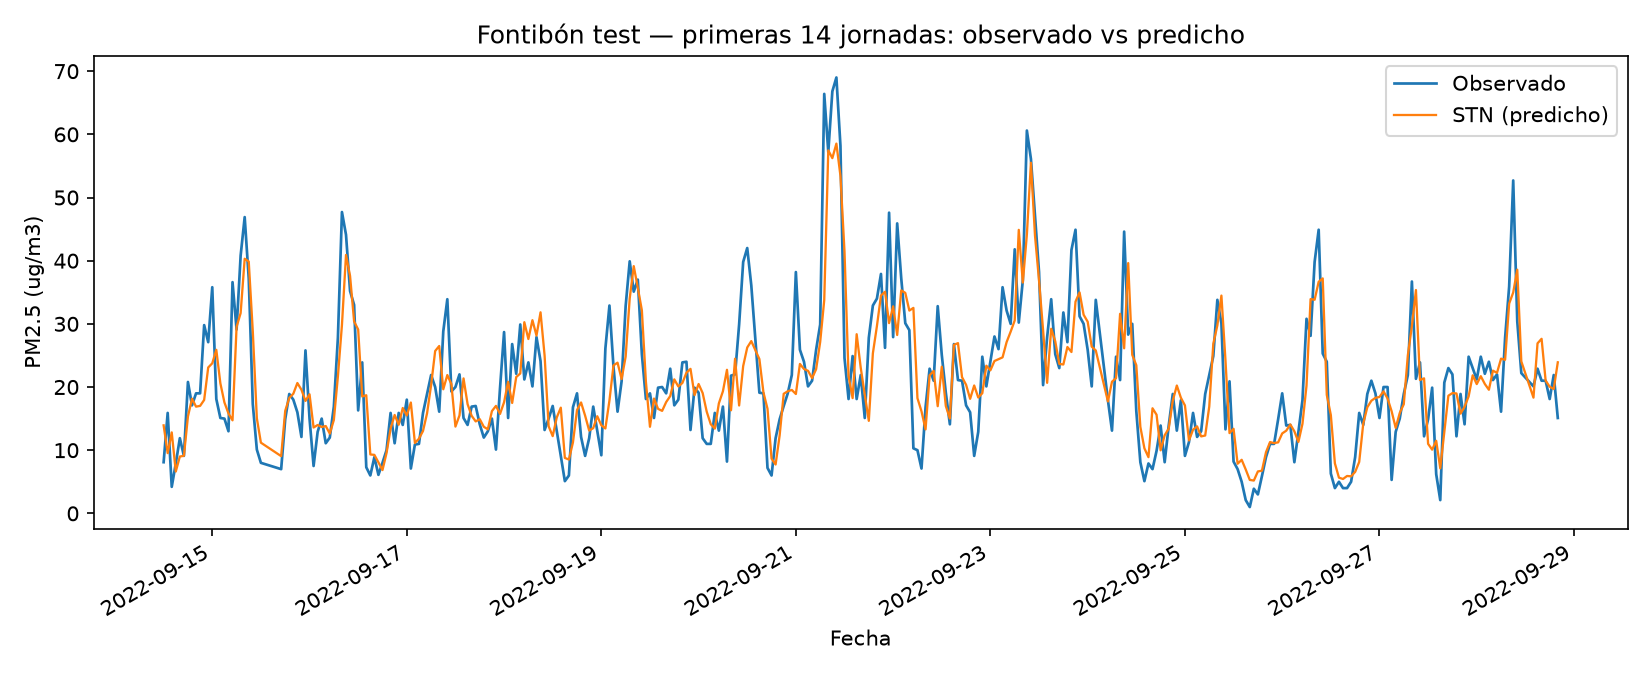

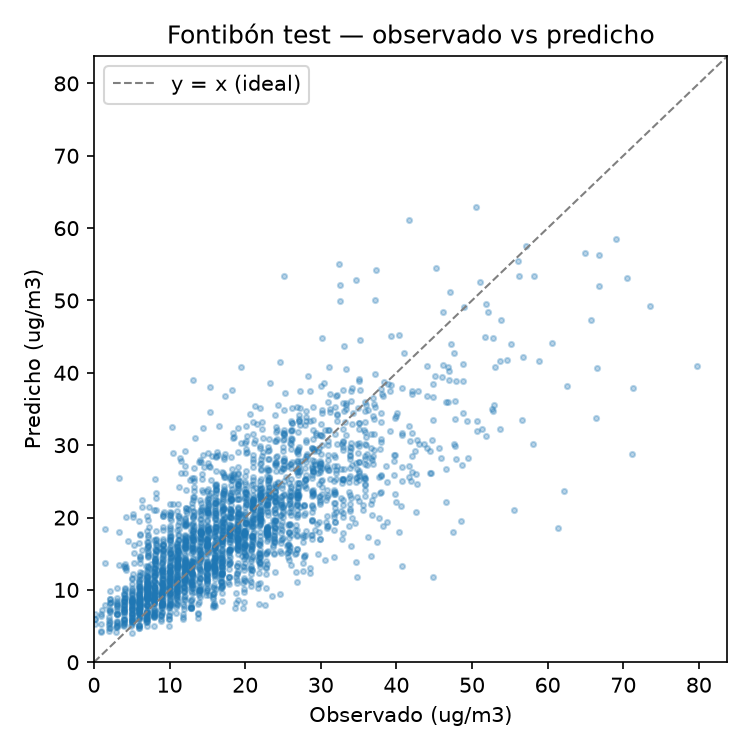

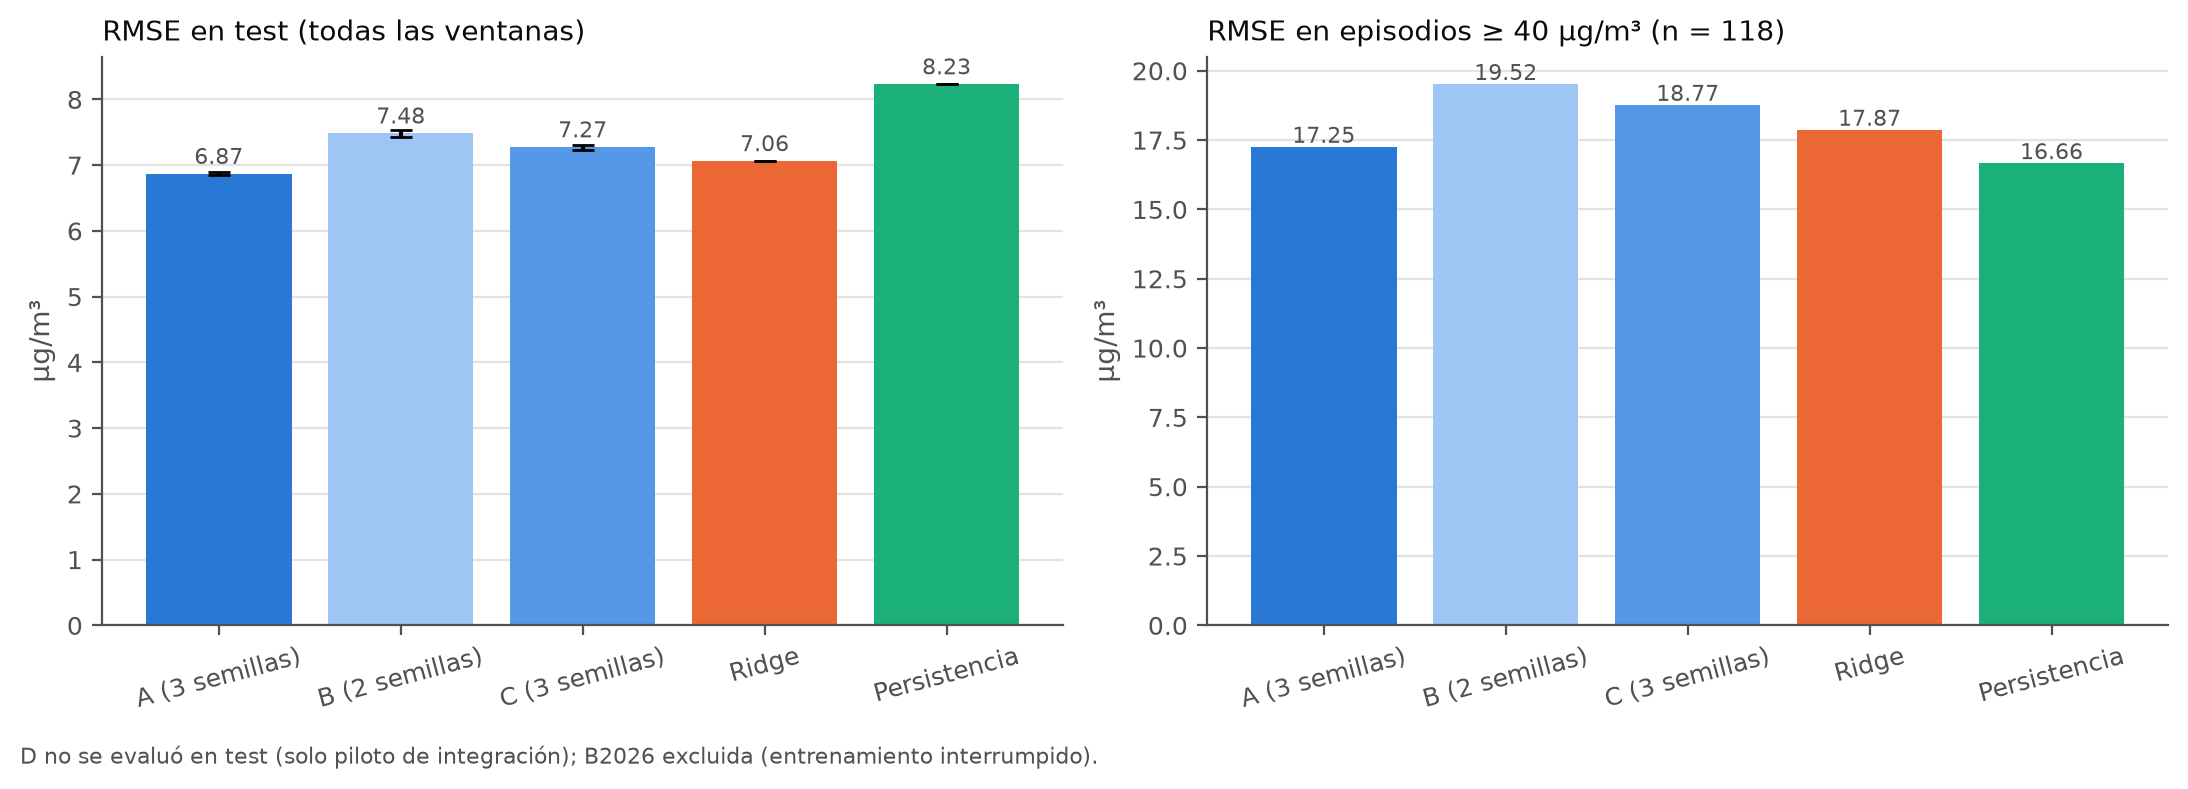

In [5]:
display(Image(filename=str(FIGS / "F3_test_final" / "test_predictions_vs_real_transfer_A_seed42.png"), width=850))
display(Image(filename=str(FIGS / "F3_test_final" / "test_scatter_transfer_A_seed42.png"), width=450))
display(Image(filename=str(FIGS / "F3_test_final" / "test_model_comparison.png"), width=900))

### Contraste con el artículo

In [6]:
r1 = load("R1_test_final_summary.json")
paper, r1a, aA = r1["paper_reference_zhang_zhang_2023"], r1["aggregate_test_metrics_ug_m3"], final["aggregate_by_config"]["A"]
pd.DataFrame({
    "Artículo (Beijing)": {"RMSE": f"{paper['RMSE']:.2f}", "R2": f"{paper['R2']:.3f}"},
    "Réplica R1 (Beijing, test 2014)": {"RMSE": f"{r1a['RMSE_mean']:.2f} ± {r1a['RMSE_std']:.2f}", "R2": f"{r1a['R2_mean']:.3f} ± {r1a['R2_std']:.3f}"},
    "Modelo A (Fontibón, test)": {"RMSE": f"{aA['RMSE']['mean']:.2f} ± {aA['RMSE']['std']:.2f}", "R2": f"{aA['R2']['mean']:.3f} ± {aA['R2']['std']:.3f}"},
})

,Artículo (Beijing),"Réplica R1 (Beijing, test 2014)","Modelo A (Fontibón, test)"
RMSE,19.04,21.13 ± 0.40,6.87 ± 0.02
R2,0.937,0.949 ± 0.002,0.616 ± 0.002


**Se conservó** la arquitectura (encoder–decoder con atención dispersa), la ventana de 24 h, el horizonte de
1 h, la pérdida MSE, Adam con tasa 10⁻⁴, el escalado MinMax y las métricas. **Cambió** la profundidad (2
encoders y 1 decoder en lugar de 3 y 2), el número de variables (3 en lugar de 8) y la validación
(cronológica en lugar de aleatoria).

El RMSE de Fontibón es menor porque sus niveles son unas cinco veces más bajos, pero el R² cae de 0,95 a
0,62. Esto se explica por la serie: Fontibón es mucho menos persistente (autocorrelación a 1 h de 0,74
frente a 0,96 en Beijing), y su variación hora a hora es más difícil de anticipar con solo PM2,5,
temperatura y punto de rocío. En Taizhou, la segunda serie del artículo y de niveles comparables, los
autores reportan R² = 0,924 con más variables, lo que apunta a la información disponible y no a la
arquitectura como el límite principal.

## 3. Auditoría mediante explicabilidad (8.2)

La auditoría busca responder qué usa el modelo para predecir y si se apoya en la señal correcta o en un
atajo. Se combinan cuatro evidencias sobre las tres semillas de A: mapas de atención, gradientes integrados
(atribución por hora y variable), ablaciones sobre test y casos sintéticos de comportamiento esperado.

Antes de leerlas se verificó que fueran fieles: los mapas de atención se extrajeron con un *forward* manual
que reproduce la predicción del modelo, y los gradientes integrados cumplen la propiedad de completitud
(las atribuciones suman el cambio de la predicción respecto a la línea base).

In [7]:
pd.DataFrame([{
    "Semilla": s,
    "Dif. máx. forward manual": v["forward_check_max_abs_diff"],
    "Error completitud IG": v["ig_completeness_error_mean"],
    "|f(x) - f(base)| medio": v["ig_mean_abs_output_change_vs_baseline"],
} for s, v in expl["seeds"].items()]).set_index("Semilla")

,Dif. máx. forward manual,Error completitud IG,|f(x) - f(base)| medio
Semilla,,,
42,2.086e-07,0.005,0.090
123,1.788e-07,0.003,0.086
2026,1.192e-07,0.004,0.089


### 3.1 Qué horas y qué variables pesan

Los gradientes integrados reparten la predicción entre cada hora y cada variable, usando como referencia una
ventana constante con la media de entrenamiento. El PM2,5 entra por el encoder y por el decoder, así que su
atribución suma ambas rutas.

,media,desv. entre semillas
ig_share_pm25,0.464,0.024
ig_share_temp,0.268,0.020
ig_share_dew,0.268,0.016
ig_share_last_hour_pm25,0.241,0.004
ig_share_last_6h_all_features,0.697,0.011


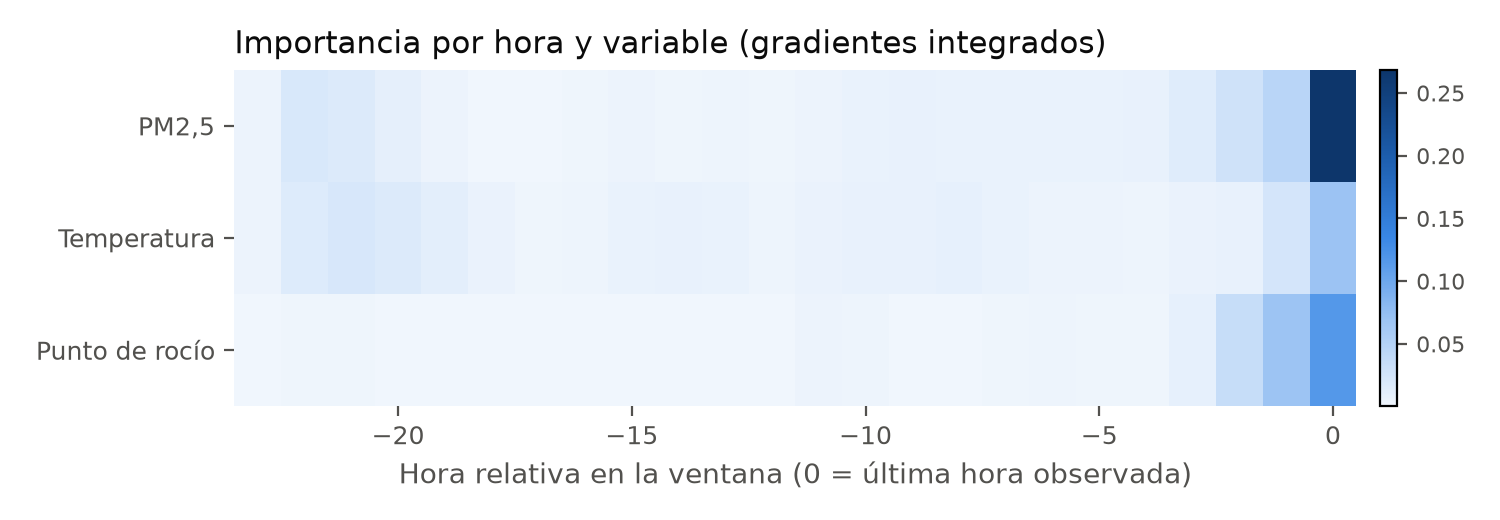

In [8]:
agg = expl["aggregate"]
display(pd.DataFrame({
    "media": {k: agg[k]["mean"] for k in ("ig_share_pm25", "ig_share_temp", "ig_share_dew",
                                         "ig_share_last_hour_pm25", "ig_share_last_6h_all_features")},
    "desv. entre semillas": {k: agg[k]["std"] for k in ("ig_share_pm25", "ig_share_temp", "ig_share_dew",
                                                       "ig_share_last_hour_pm25", "ig_share_last_6h_all_features")},
}))
display(Image(filename=str(FIGS / "F3_explainability" / "integrated_gradients_hour_feature.png"), width=850))

**Lectura.** El 70 % de la atribución corresponde a las últimas 6 horas y el 24 % solo al PM2,5 de la
última hora. La meteorología cuenta (temperatura y punto de rocío suman el 54 %), sobre todo en las horas
más recientes, y el patrón es casi idéntico entre semillas (desviaciones de 0,01 a 0,02). La red aprendió
una dependencia físicamente razonable: la contaminación de la próxima hora depende sobre todo de la actual
y de las condiciones meteorológicas recientes.

### 3.2 Mapas de atención

La figura muestra, para la primera capa del encoder (la única cuyas posiciones todavía corresponden a horas
reales), cuánta atención recibe cada hora en promedio sobre todo el test.

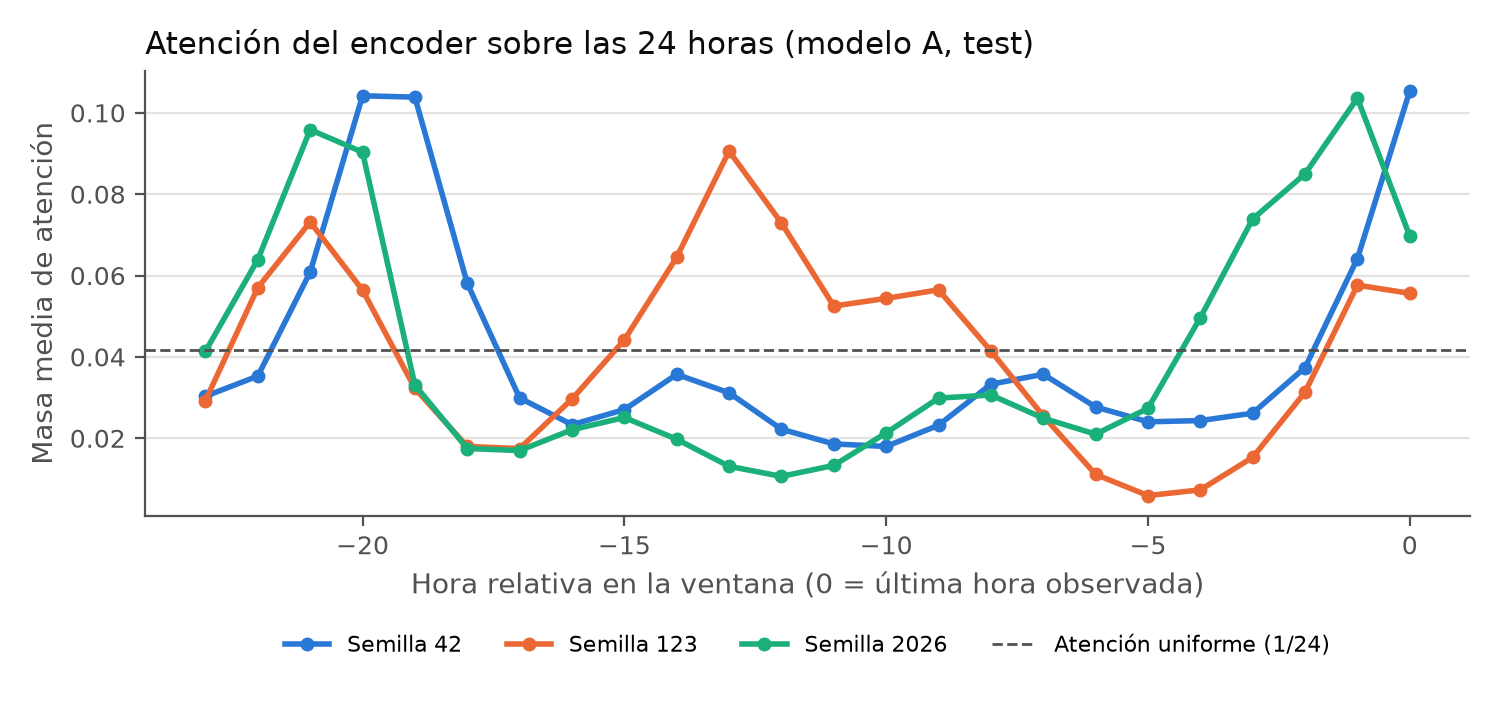

,Atención en últimas 6 h,Referencia uniforme,IG en últimas 6 h,Posición a predecir activa en el decoder
Semilla,,,,
42,0.282,0.25,0.690,0.922
123,0.173,0.25,0.709,0.766
2026,0.409,0.25,0.691,1.000


In [9]:
display(Image(filename=str(FIGS / "F3_explainability" / "attention_encoder_by_hour.png"), width=850))
pd.DataFrame([{
    "Semilla": s,
    "Atención en últimas 6 h": v["attention_enc_long1_mass_last_6h"],
    "Referencia uniforme": v["attention_enc_long1_mass_uniform_reference_last_6h"],
    "IG en últimas 6 h": v["ig_share_last_6h_all_features"],
    "Posición a predecir activa en el decoder": v["dec_pred_position_selected_frac"],
} for s, v in expl["seeds"].items()]).set_index("Semilla")

**Lectura.** Las tres semillas tienen métricas y atribuciones casi idénticas, pero distribuyen la atención
de forma muy distinta: la masa sobre las últimas 6 horas va de 0,17 a 0,41, mientras que la atribución de
esas mismas horas se mantiene en 0,69–0,71. Además, en la semilla 123 la posición que se predice queda
fuera de la autoatención dispersa del decoder en el 23 % de las ventanas. El modelo llega a la misma
función por rutas internas diferentes, así que **los pesos de atención por sí solos no son una explicación
estable**: aquí se usan como evidencia complementaria, y la lectura se apoya en las atribuciones y las
ablaciones.

### 3.3 Matrices de atención consulta × clave

Las figuras siguientes muestran los **pesos reales** que devuelve la atención dispersa de la primera capa del
encoder (`enc0_long1`) para la semilla 42, sin promediar:
- cada panel es una cabeza;
- cada fila es una hora que actúa como consulta, y cada columna una hora observada (clave);
- las filas grises son consultas que la atención dispersa no seleccionó (su salida se rellena con cero).

Las ventanas de ejemplo se eligieron con reglas fijas que no dependen del error: la más cercana a la mediana
de su grupo (normal < 40 con cambio pequeño; alto ≥ 40). La semilla 42 se usa como ejemplo y no representa a
las otras dos.

In [10]:
att = load("F3_attention_matrices_summary.json")
pd.DataFrame({
    "Semilla": list(att["seeds"]),
    "Forma de los pesos": [str(v["attention_shape_enc0_long1"]) for v in att["seeds"].values()],
    "Dif. forward manual": [v["forward_check_max_abs_diff"] for v in att["seeds"].values()],
    "Dif. con predicciones guardadas": [v["pred_check_vs_saved_csv_max_abs"] for v in att["seeds"].values()],
}).set_index("Semilla")

,Forma de los pesos,Dif. forward manual,Dif. con predicciones guardadas
Semilla,,,
42,"[2574, 4, 12, 24]",2.086e-07,2.299e-05
123,"[2574, 4, 12, 24]",1.788e-07,1.723e-05
2026,"[2574, 4, 12, 24]",1.192e-07,1.280e-05


normal: 2022-09-17 08:00:00 | real 16.1 | predicción 26.5 | última hora 20.0


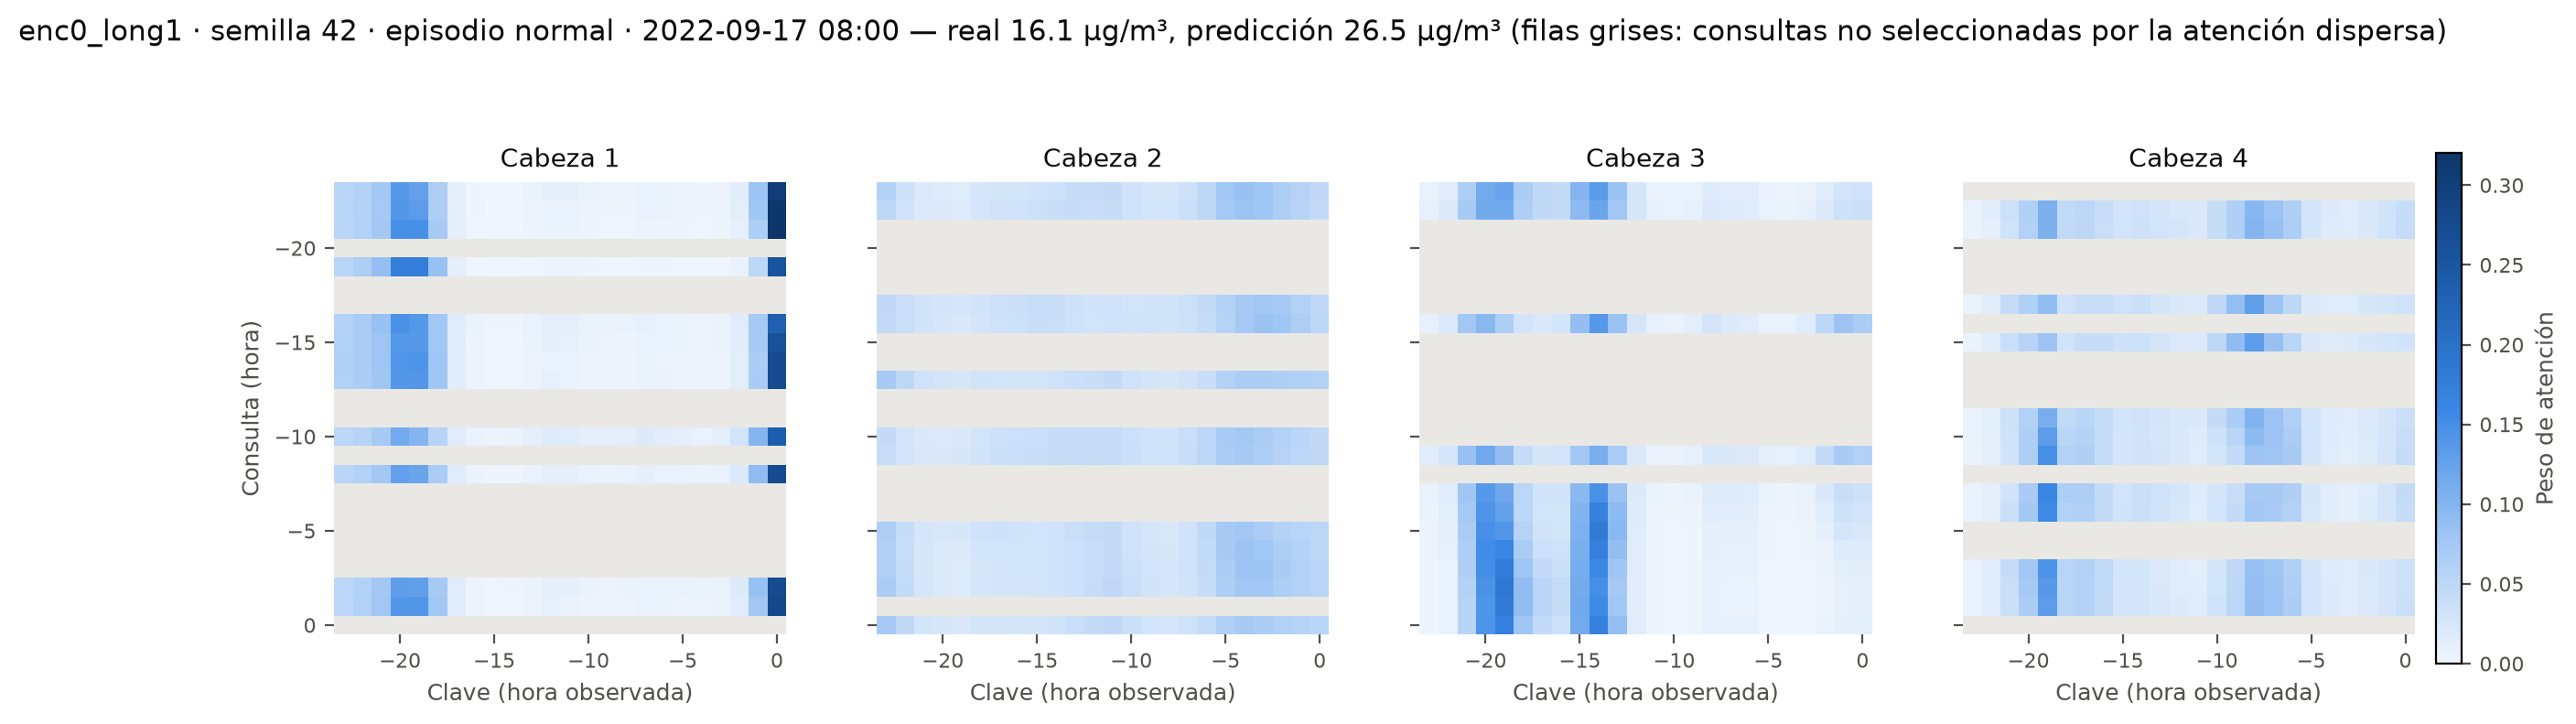

high: 2022-10-25 14:00:00 | real 47.5 | predicción 18.0 | última hora 25.8


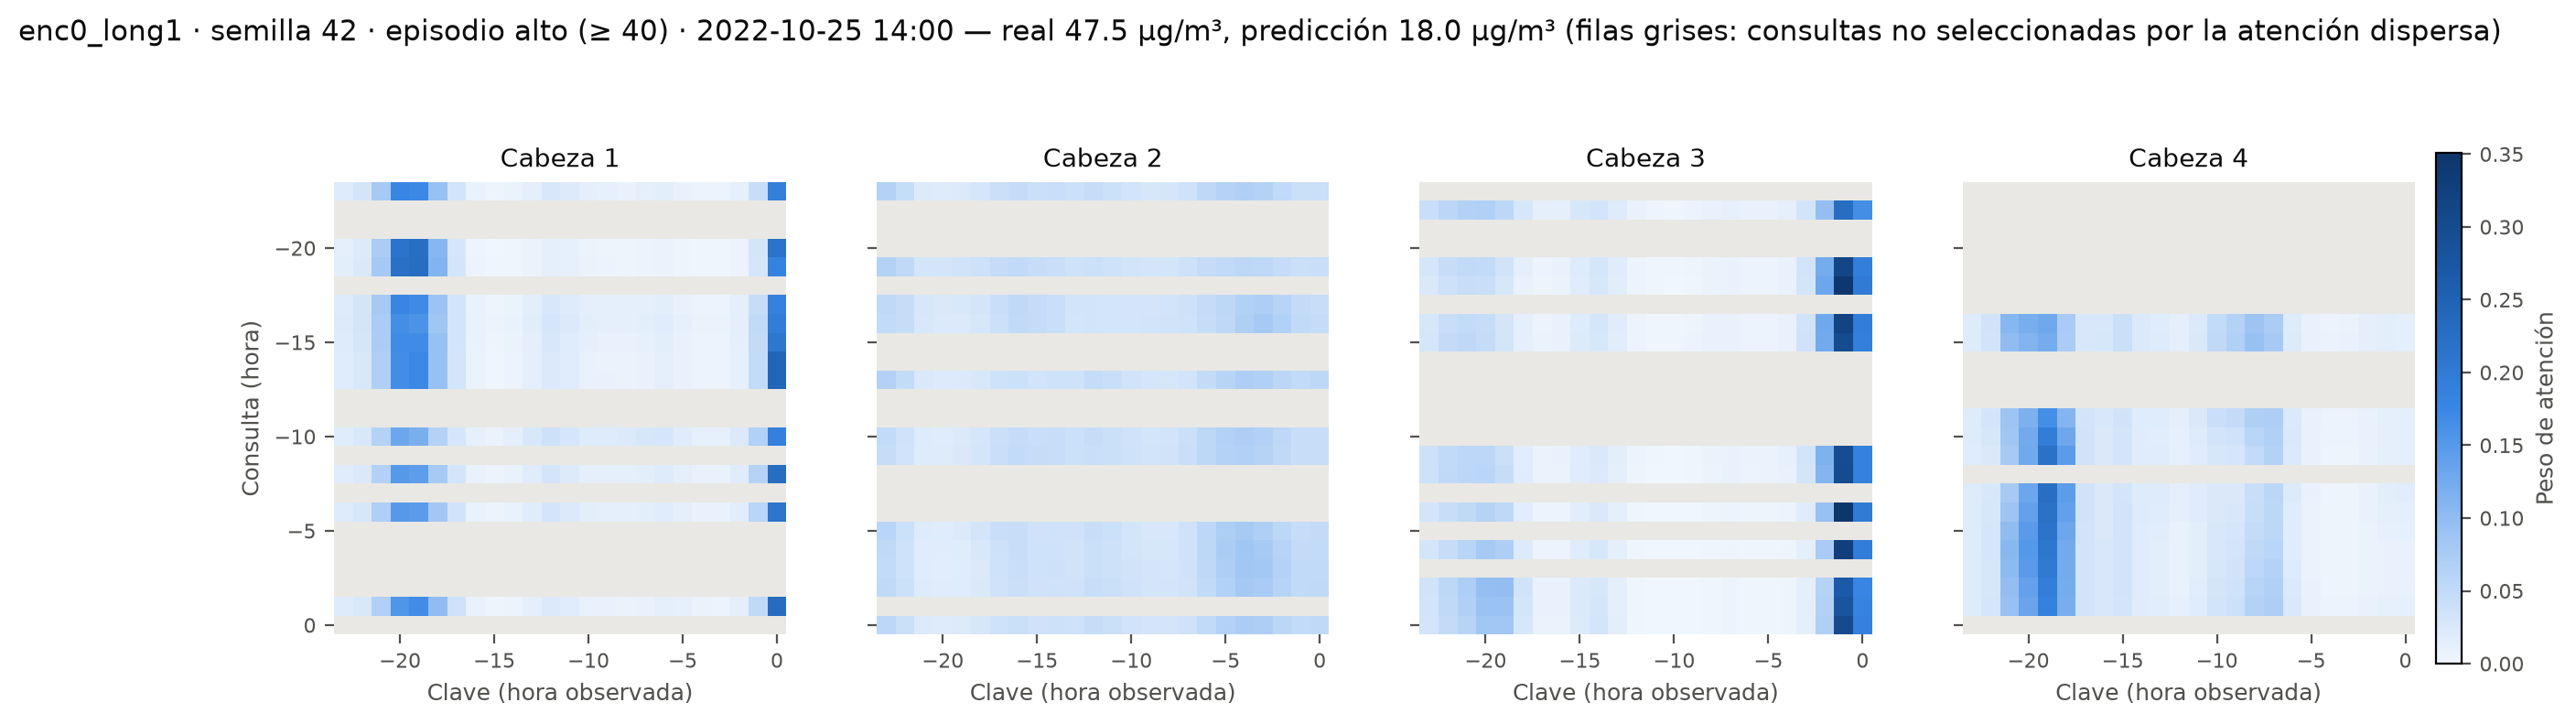

In [11]:
for tag in ("normal", "high"):
    e = att[f"example_{tag}"]
    print(f"{tag}: {e['timestamp']} | real {e['y_real']:.1f} | predicción {e['pred_seed42']:.1f} | última hora {e['last_observed']:.1f}")
    display(Image(filename=str(FIGS / "F3_attention" / f"attention_matrix_{tag}_seed42.png"), width=1000))

**Lectura.** En las cuatro cabezas aparecen franjas verticales: casi todas las consultas atienden las mismas
claves, sea cual sea la hora que consulta.
- La cabeza 1 concentra peso en las horas −20/−19 y en la última hora.
- La cabeza 3, en la última hora.
- La cabeza 4, en las horas −21 a −18.
- La cabeza 2 reparte la atención casi uniformemente.

El patrón es muy parecido en el episodio normal y en el alto.

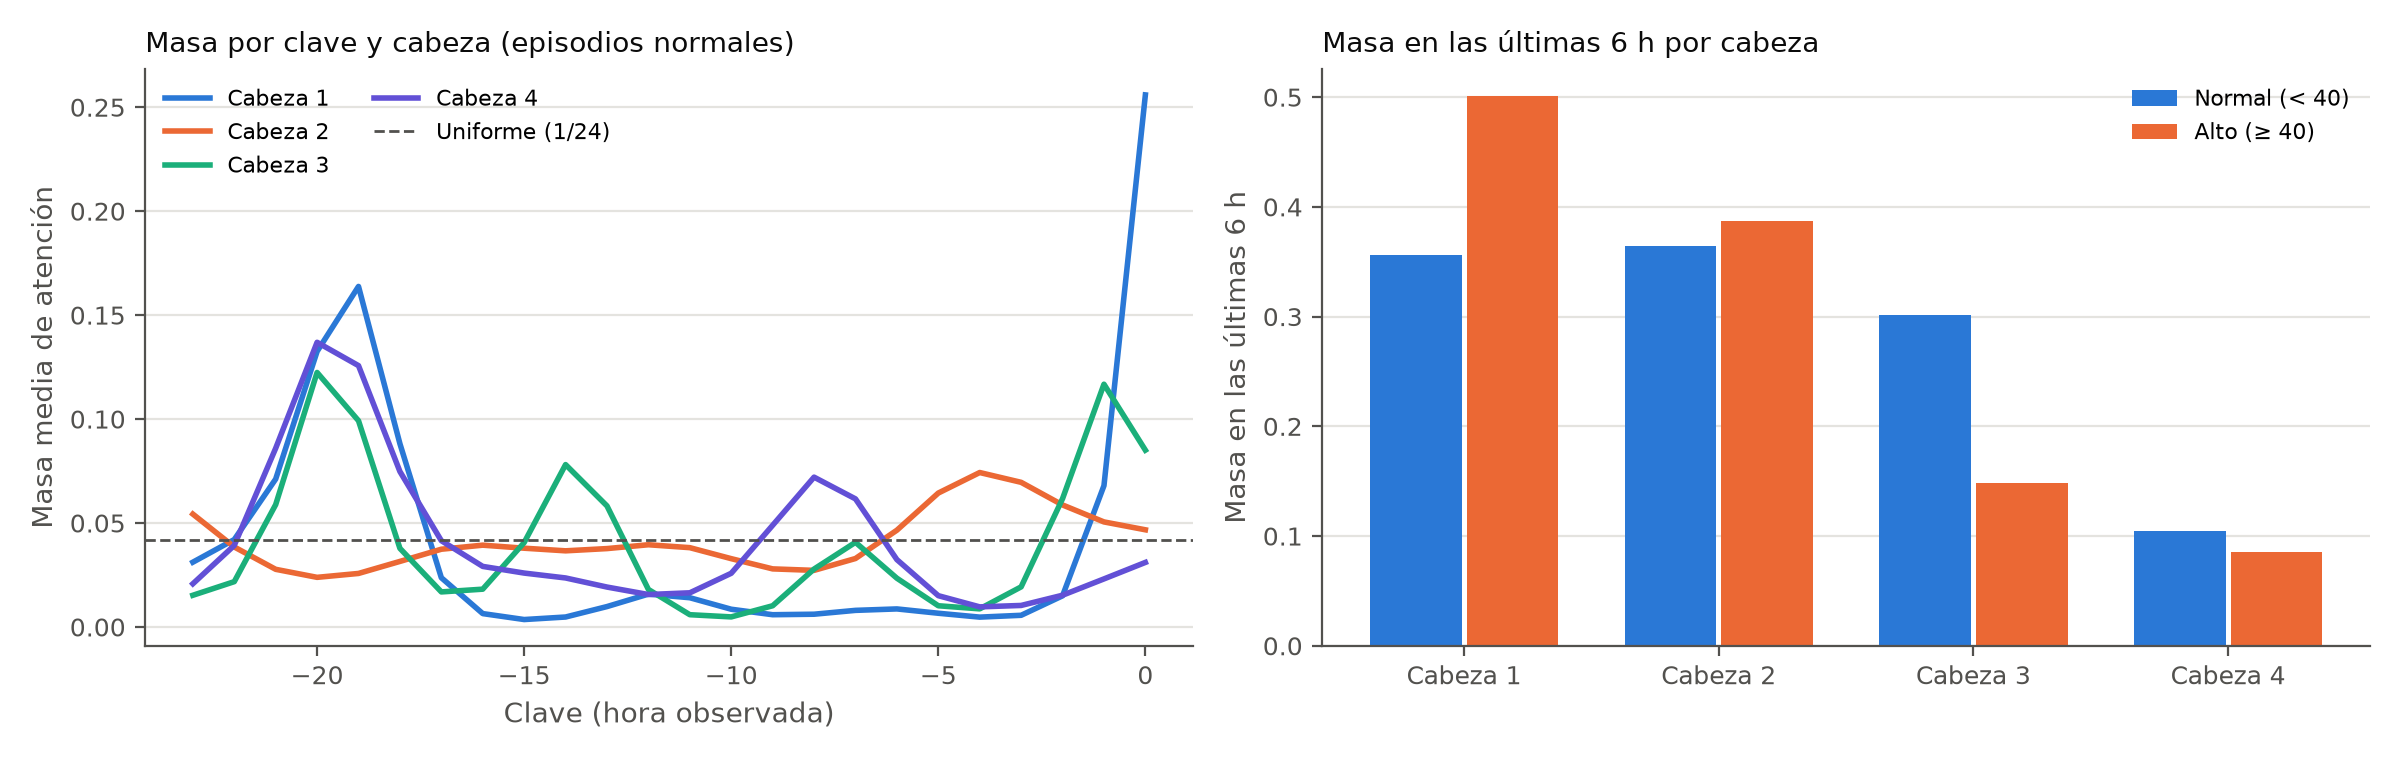

,Cabeza 1,Cabeza 2,Cabeza 3,Cabeza 4
Masa últimas 6 h (normal),0.356,0.364,0.302,0.104
Masa últimas 6 h (alto),0.501,0.387,0.148,0.085
Horas atrás promedio (normal),12.045,10.246,11.570,14.226
Entropía normalizada (normal),0.743,0.980,0.795,0.888


In [12]:
display(Image(filename=str(FIGS / "F3_attention" / "attention_heads_seed42.png"), width=950))
g = att["seeds"]["42"]["groups"]
pd.DataFrame({f"Cabeza {h + 1}": {
    "Masa últimas 6 h (normal)": g["normal"]["per_head_mass_last6h"][h],
    "Masa últimas 6 h (alto)": g["high"]["per_head_mass_last6h"][h],
    "Horas atrás promedio (normal)": g["normal"]["per_head_mean_key_hours_back"][h],
    "Entropía normalizada (normal)": g["normal"]["per_head_entropy"][h],
} for h in range(4)})

**Lectura.** Las cabezas sí atienden patrones distintos: una es casi uniforme, dos son concentradas y una
mira horas antiguas. Entre episodios normales y altos, unas cabezas aumentan su peso reciente y otras lo
reducen, sin una dirección común. No se asigna a ninguna cabeza un significado físico.

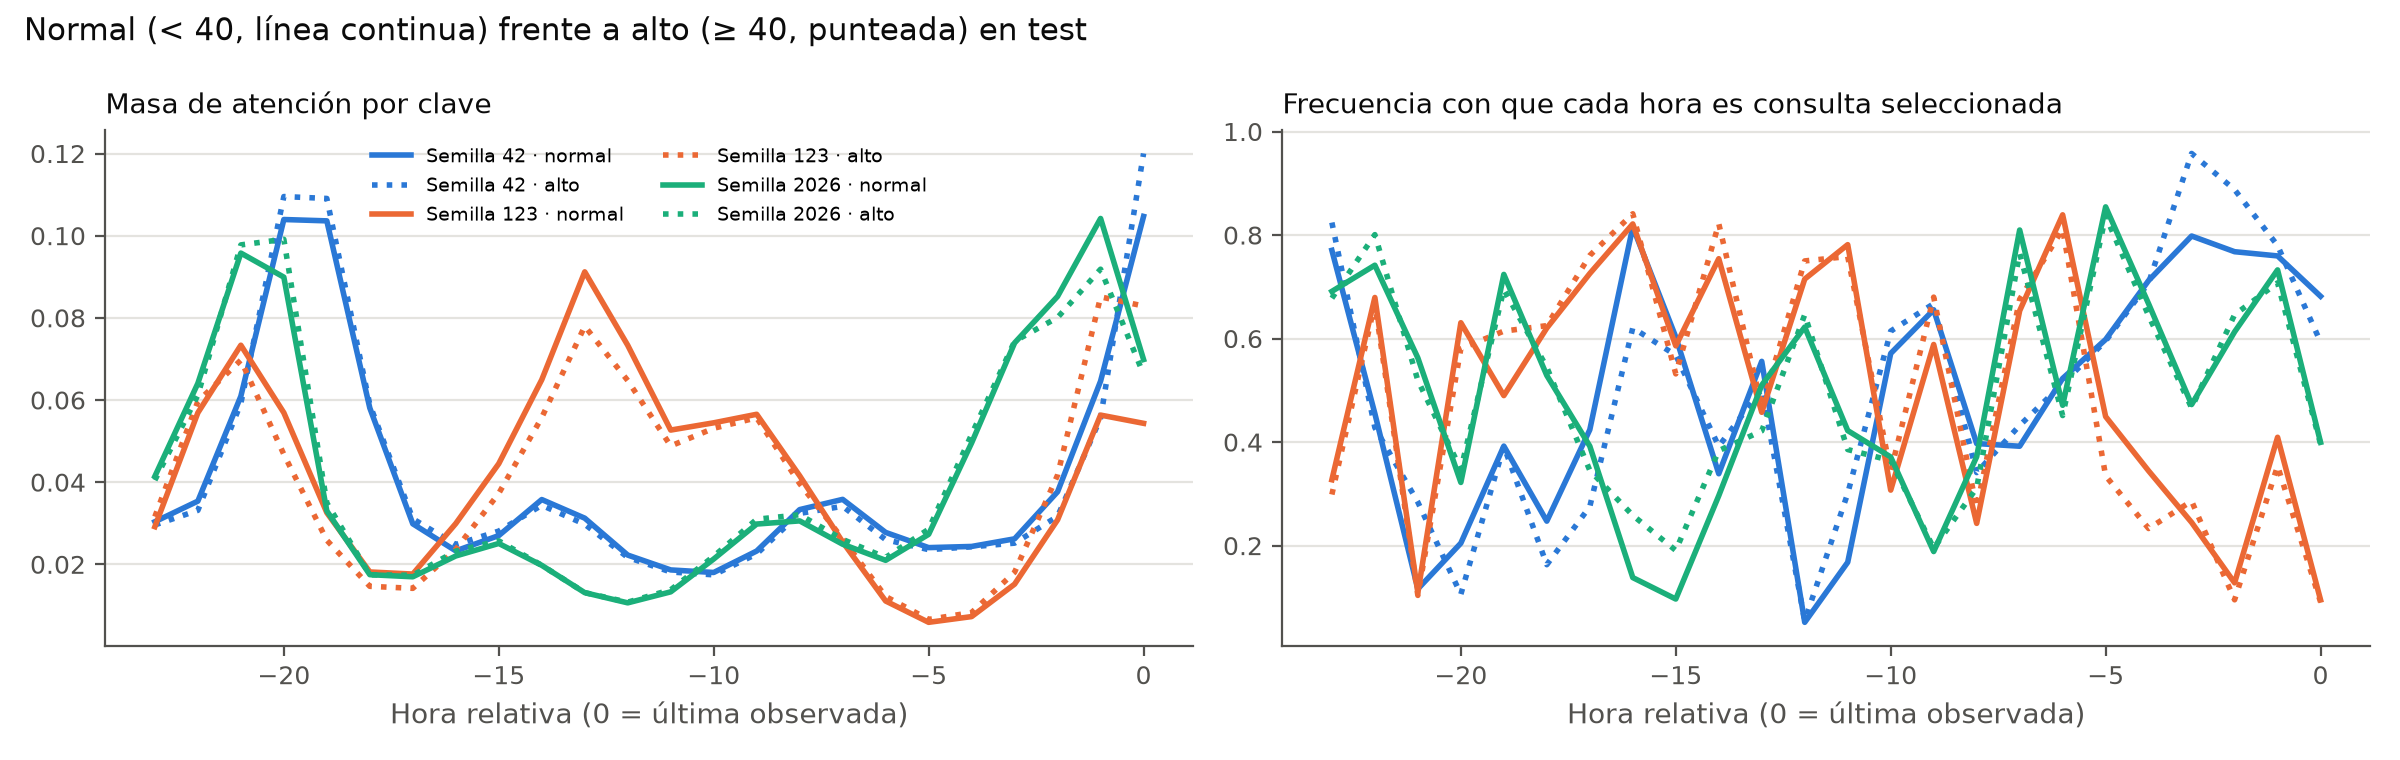

Semilla,123,2026,42
Métrica,,,
mass_last6h,0.073,-0.017,-0.001
mean_key_hours_back,-1.024,0.255,0.067
normalized_entropy,-0.006,-0.003,-0.022


Mismo signo en las 3 semillas: {'mass_last6h': False, 'mean_key_hours_back': False, 'normalized_entropy': True}


In [13]:
display(Image(filename=str(FIGS / "F3_attention" / "attention_normal_vs_high.png"), width=950))
rows = []
for s, v in att["seeds"].items():
    for k in ("mass_last6h", "mean_key_hours_back", "normalized_entropy"):
        rows.append({"Semilla": s, "Métrica": k, "Alto - normal": v["high_minus_normal"][k]})
display(pd.DataFrame(rows).pivot(index="Métrica", columns="Semilla", values="Alto - normal"))
print("Mismo signo en las 3 semillas:", {k: v["same_sign_all_seeds"] for k, v in att["high_minus_normal_consistency"].items()})

**Lectura.** Dentro de cada semilla, las curvas de episodios normales y altos casi se superponen.
- La masa en las últimas 6 horas y la posición media de las claves no cambian con un signo consistente entre
  semillas.
- La entropía es algo menor en episodios altos en las tres semillas, pero la diferencia es mínima.

**No hay una diferencia reproducible: la atención no se reorganiza durante los episodios.**

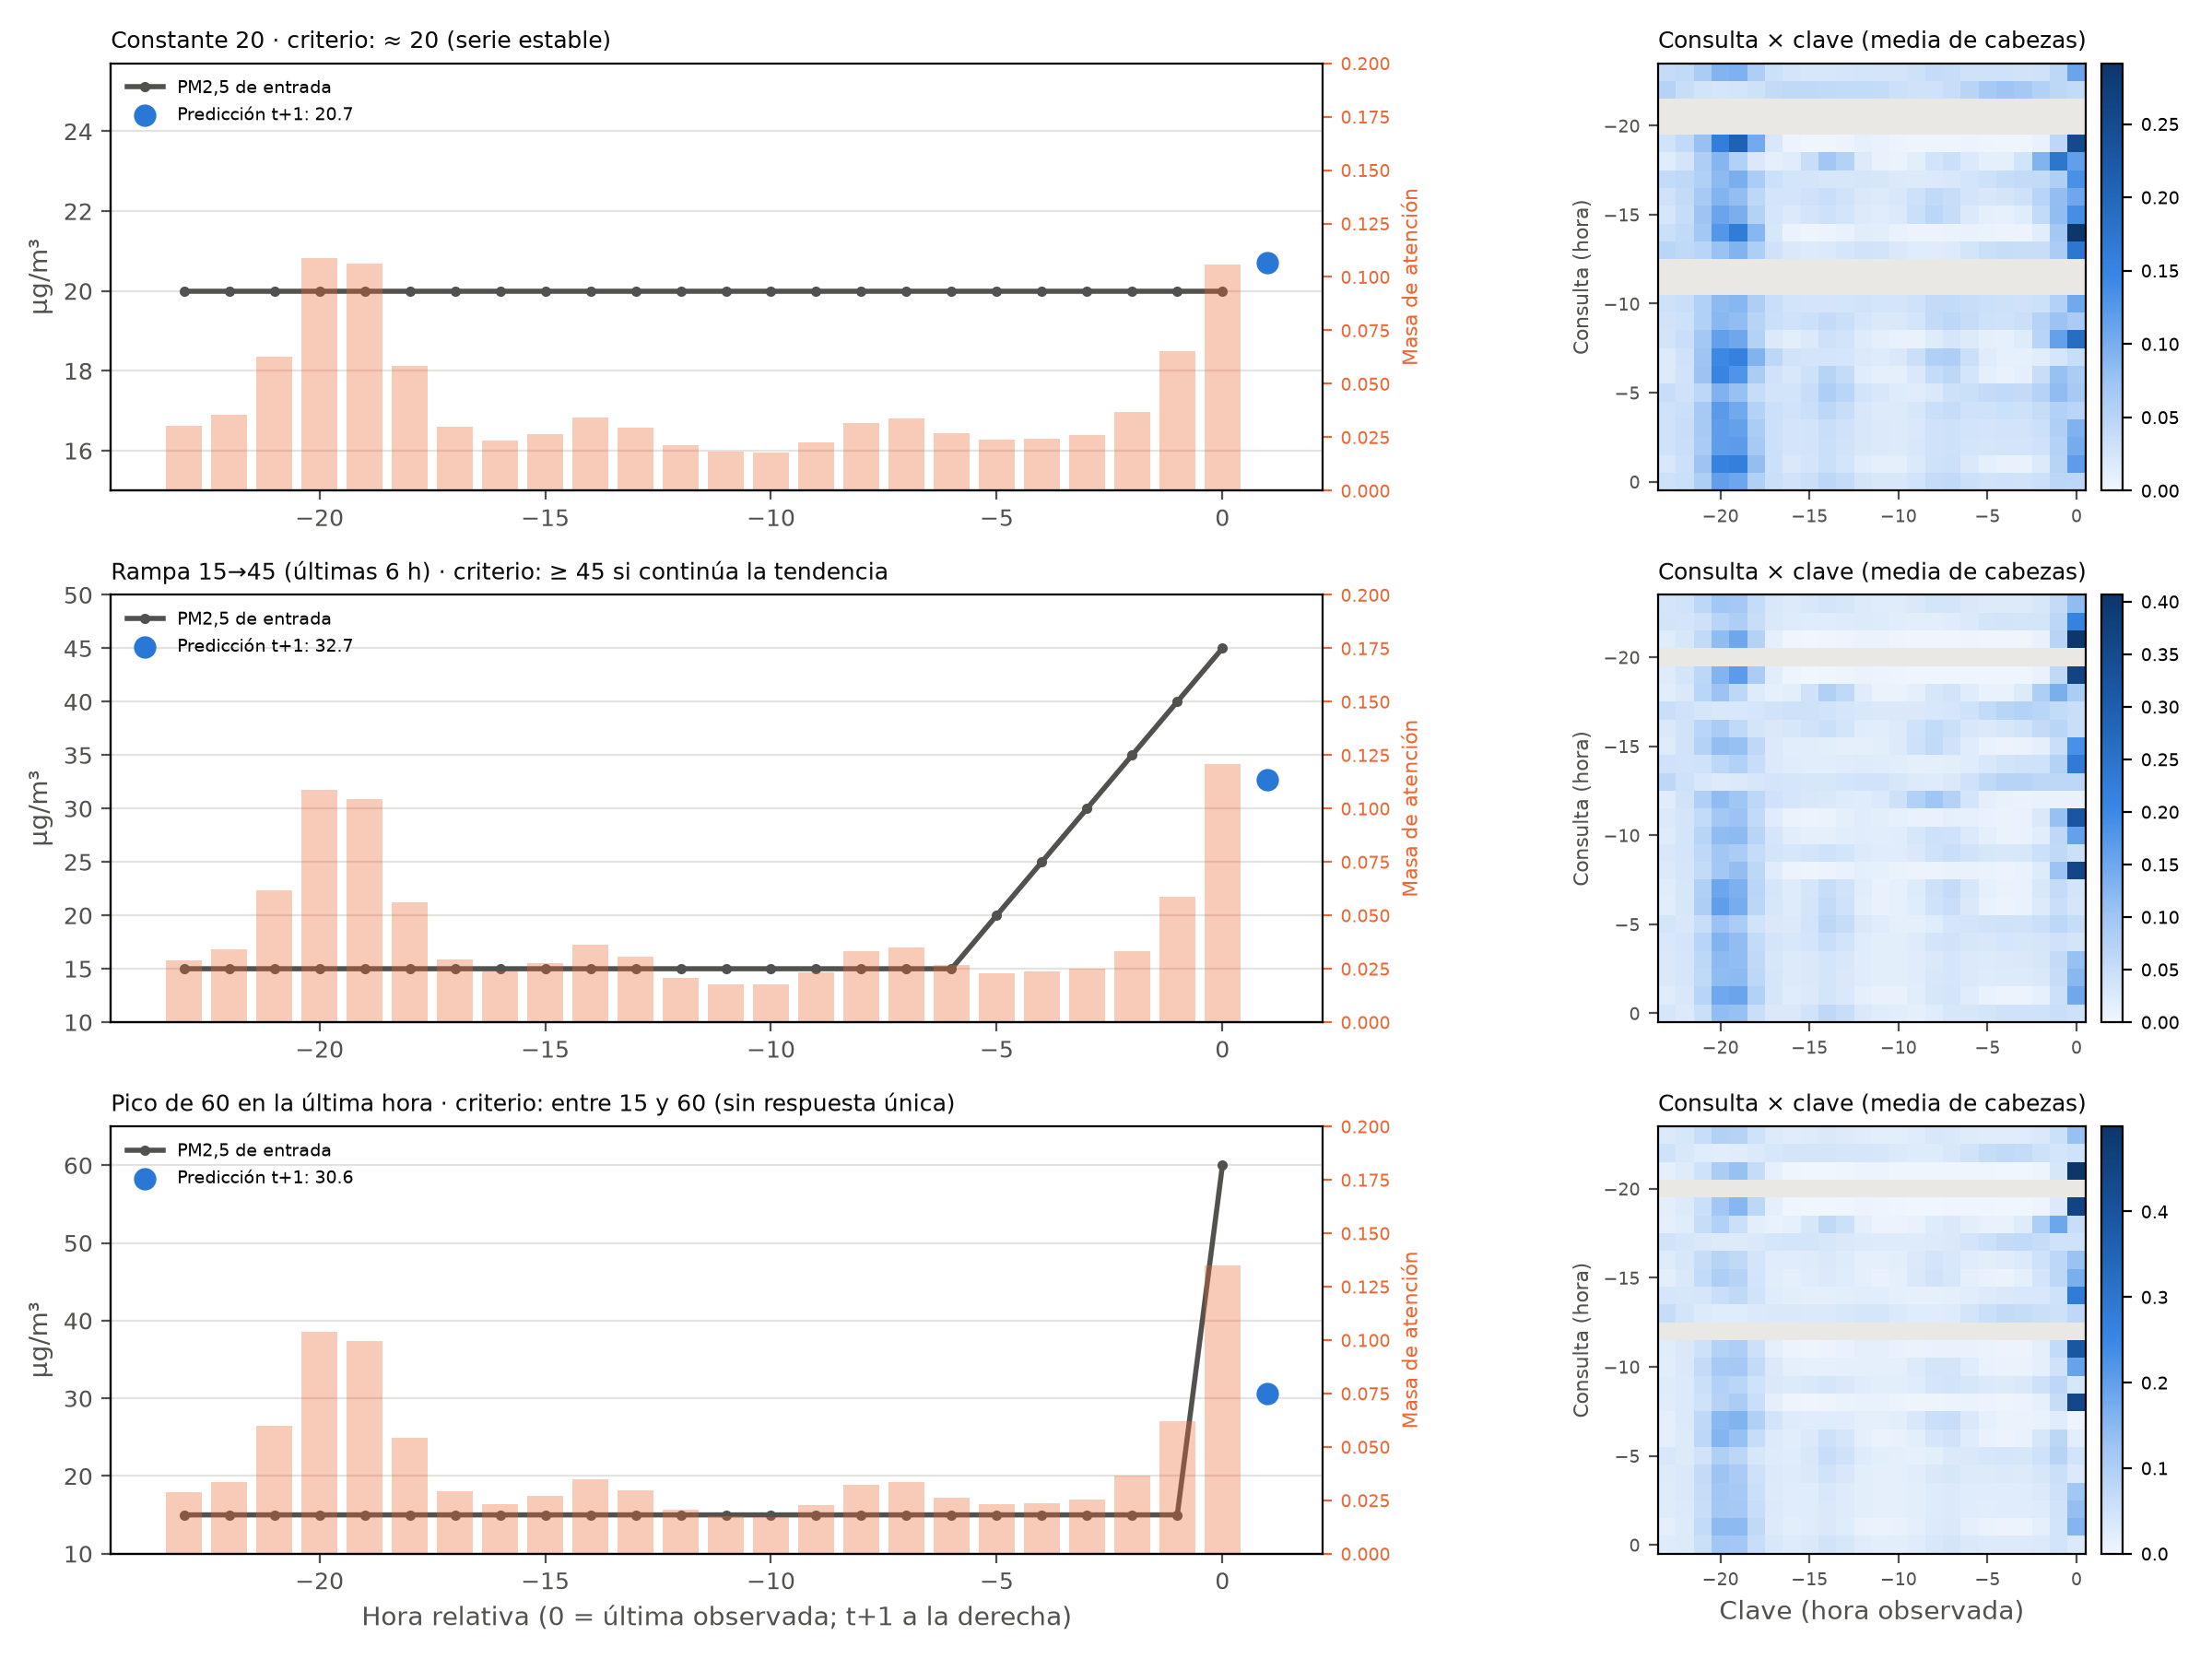

,Predicción (semilla 42),Criterio de razonabilidad,Masa última hora,Masa últimas 6 h
constante_20,20.704,≈ 20 (serie estable),0.106,0.282
rampa_15_a_45_ultimas_6h,32.701,≥ 45 si continúa la tendencia,0.121,0.285
pico_en_la_ultima_hora,30.63,entre 15 y 60 (sin respuesta única),0.135,0.305


In [14]:
display(Image(filename=str(FIGS / "F3_attention" / "attention_synthetic_seed42.png"), width=950))
pd.DataFrame({k: {"Predicción (semilla 42)": v["pred_seed42"], "Criterio de razonabilidad": v["reasonableness_criterion"],
                  "Masa última hora": v["mass_last_hour"], "Masa últimas 6 h": v["mass_last6h"]}
              for k, v in att["synthetic_cases_seed42"].items()}).T

**Lectura.** Las tres entradas producen predicciones muy distintas, pero una distribución de atención casi
igual. En estos casos, la atención parece estar dominada por la posición más que por el contenido: lo que cambia la predicción son los
valores que se atienden y las capas siguientes. Estos casos no tienen valor real, solo un criterio de
razonabilidad.

**Lectura integrada.**
- La **atención** dice qué posiciones reciben peso: un patrón casi fijo, distinto en cada semilla e igual en
  episodios normales y altos.
- Los **gradientes integrados** dicen qué entradas afectan la salida: las últimas horas y la meteorología, de
  forma estable.
- Las **ablaciones** dicen qué información necesita el modelo: el orden temporal y la meteorología.

Ninguna fuente sola es causal; juntas sostienen la conclusión de la sección siguiente.

### 3.4 ¿Señal o atajo? Persistencia, ablaciones y casos sintéticos de comportamiento esperado

,42,123,2026
corr_pred_real,0.784,0.786,0.785
corr_pred_last_observed,0.906,0.895,0.890
slope_pred_on_last_observed,0.725,0.700,0.717
fraction_of_rise_captured_mean,0.223,0.249,0.251
fraction_of_fall_captured_mean,0.397,0.385,0.402


,42,123,2026
Cambio de RMSE al alterar la entrada,,,
meteo_neutralizada,0.697,0.768,0.599
orden_temporal_permutado,4.151,4.174,4.571
historia_pm25_plana_ultimo_valor,0.798,0.692,0.793


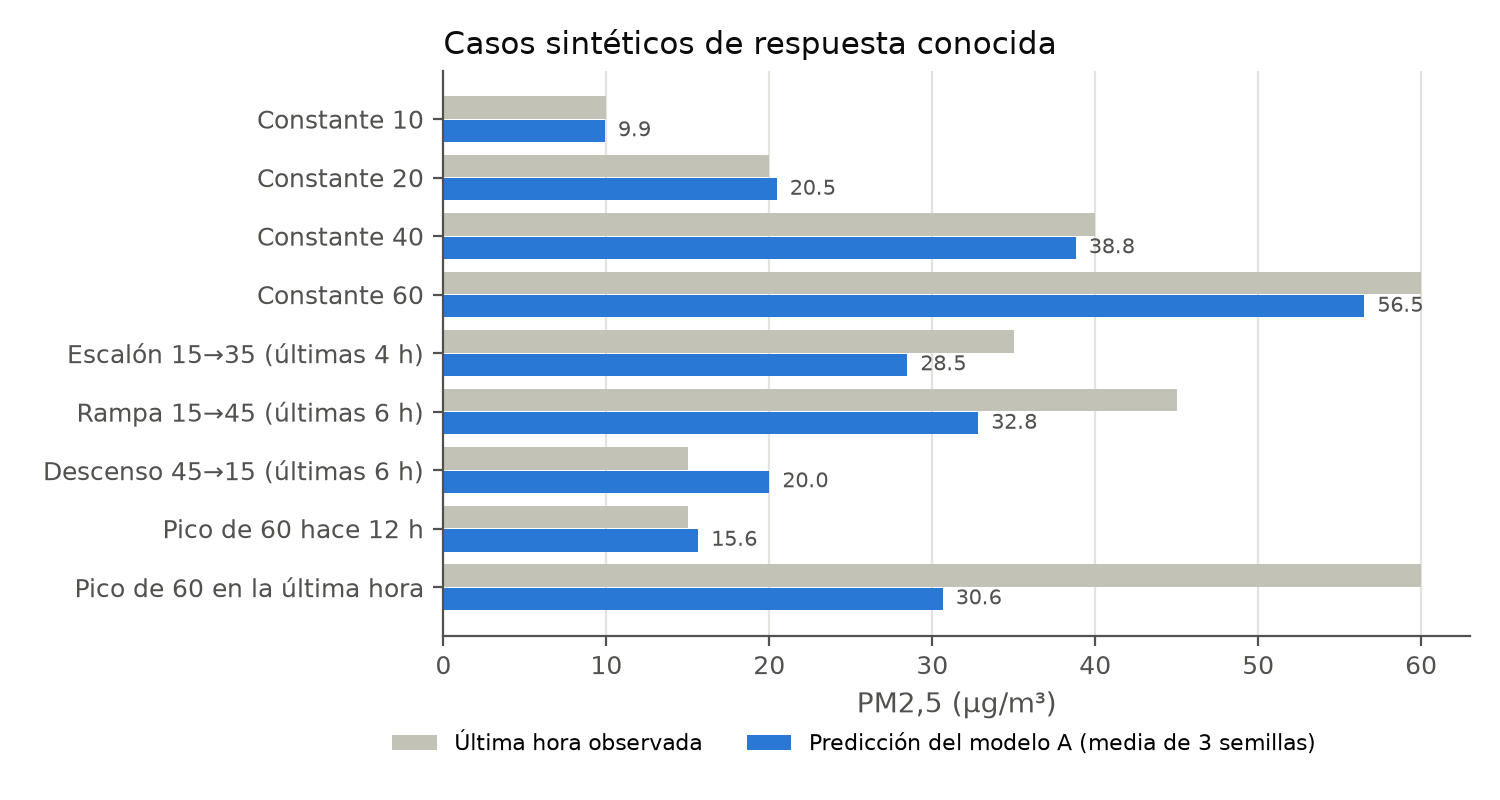

In [15]:
display(pd.DataFrame({s: {k: v["shortcut_persistence"][k] for k in (
    "corr_pred_real", "corr_pred_last_observed",
    "slope_pred_on_last_observed", "fraction_of_rise_captured_mean", "fraction_of_fall_captured_mean")}
    for s, v in expl["seeds"].items()}))
display(pd.DataFrame({s: {k: (a["rmse_change_vs_original"]) for k, a in v["ablations_test"].items() if k != "original_rmse"}
                      for s, v in expl["seeds"].items()}).rename_axis("Cambio de RMSE al alterar la entrada"))
display(Image(filename=str(FIGS / "F3_explainability" / "synthetic_cases.png"), width=800))

**Lectura.**

- **No es una simple copia de la última hora.** Aplanar la historia de PM2,5 sube el RMSE (+0,76),
  neutralizar la meteorología también (+0,69) y desordenar las horas lo dispara (+4,30). Las series
  constantes se reproducen (10 → 9,9; 40 → 38,8) y un pico ocurrido hace 12 horas se ignora (15,6 sobre una
  base de 15), que es lo esperable.
- **Pero sí se comporta como una persistencia suavizada con regresión a la media.** Su predicción se
  correlaciona más con la última hora observada (0,90) que con el valor real que debe predecir (0,785).
  Solo capta el 24 % de cada subida y el 40 % de
  cada bajada. En los casos sintéticos amortigua todo cambio reciente: un escalón 15→35 se predice en 28,5
  y un pico de 60 en la última hora en 30,6.
- **Conclusión de la auditoría.** En las comprobaciones realizadas no se encontró evidencia de que la
  imputación o el mes expliquen este patrón: las ventanas con datos imputados tienen un error similar y el
  desempeño se mantiene estable entre los meses observados. El modelo aprendió una estrategia
  conservadora que minimiza el error cuadrático promedio a costa de reaccionar tarde a los cambios. Esto
  ayuda a explicar su principal falla, que se examina a continuación.

## 4. Análisis de fallas (8.3)

Para la lectura por grupos, "A" es el promedio de las predicciones de las tres semillas. Los errores se
definen como predicción menos valor real.

,n,RMSE A,Sesgo A,RMSE Ridge,RMSE persistencia
"PM2,5 real (µg/m³)",,,,,
<10,556.0,5.068,3.407,5.709,5.364
10–20,1018.0,5.329,1.790,5.559,7.314
20–30,640.0,5.810,-1.632,5.869,8.348
30–40,242.0,8.954,-5.338,8.888,10.485
≥40,118.0,17.184,-13.952,17.868,16.664


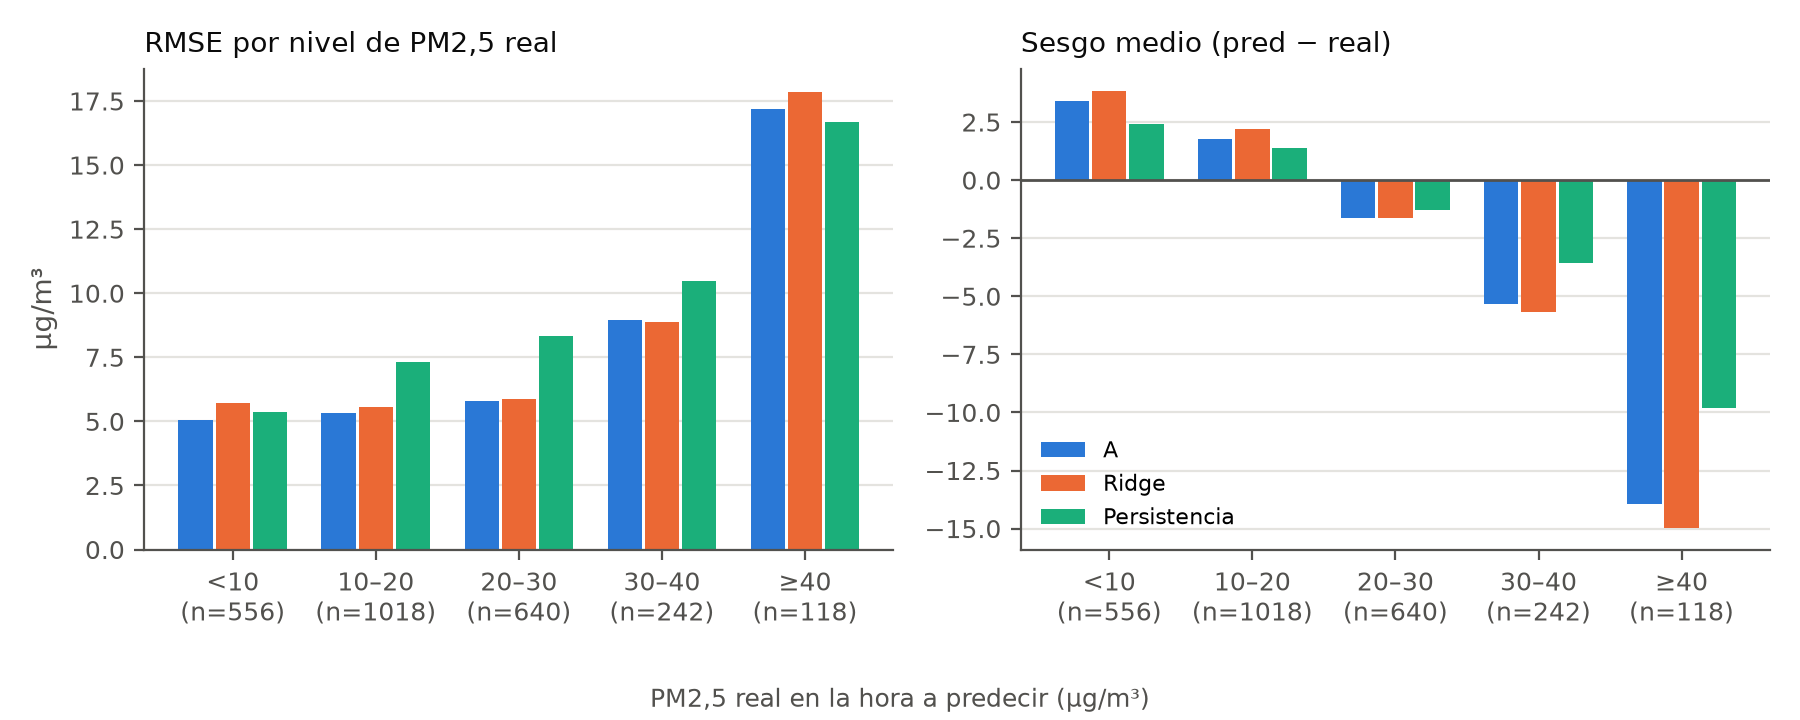

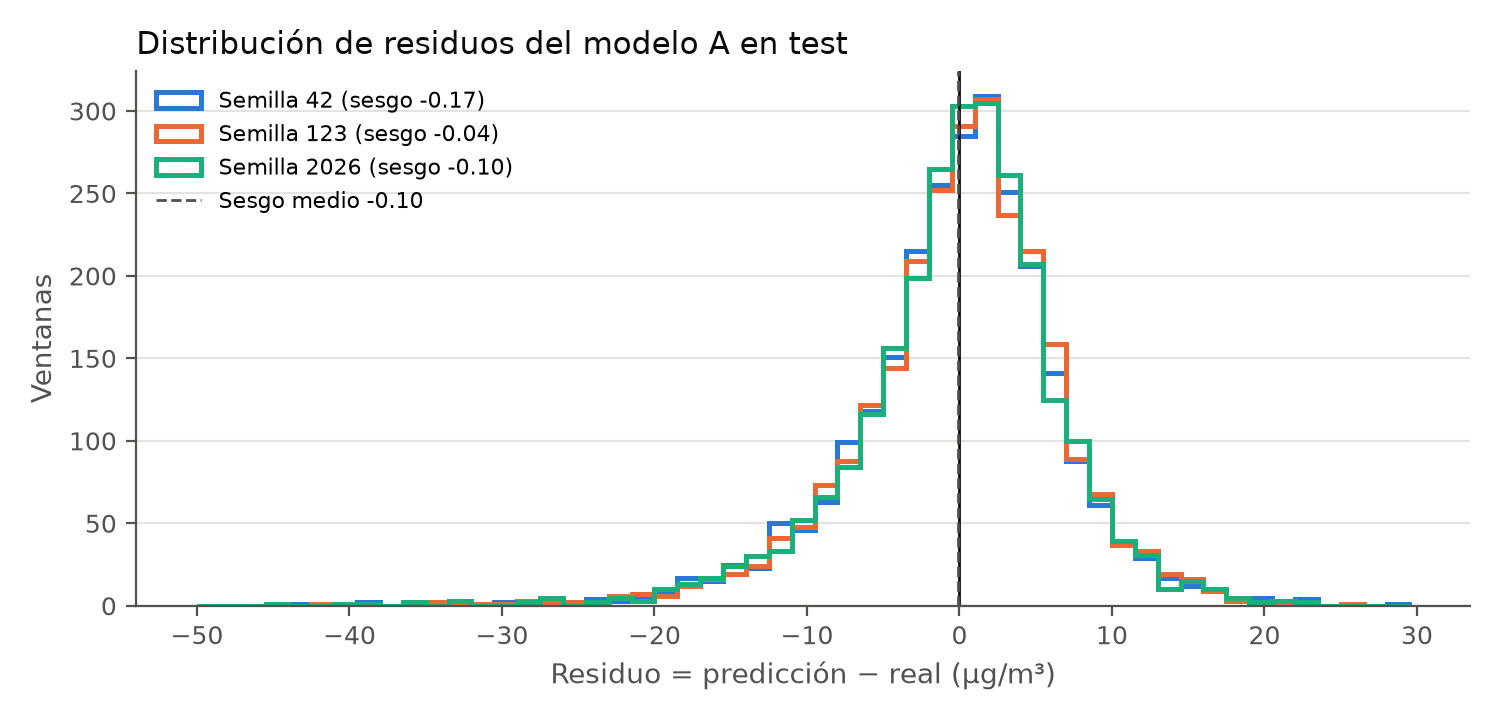

In [16]:
lvl = fail["by_level"]
display(pd.DataFrame({b: {"n": lvl[b]["A"]["n"],
                          "RMSE A": lvl[b]["A"]["RMSE"], "Sesgo A": lvl[b]["A"]["bias"],
                          "RMSE Ridge": lvl[b]["Ridge"]["RMSE"], "RMSE persistencia": lvl[b]["Persistencia"]["RMSE"]}
                      for b in lvl}).T.rename_axis("PM2,5 real (µg/m³)"))
display(Image(filename=str(FIGS / "F3_failure_analysis" / "error_by_level.png"), width=900))
display(Image(filename=str(FIGS / "F3_test_final" / "test_residual_distribution.png"), width=750))

Por tipo de cambio en la hora a predecir


,n,RMSE A,Sesgo A,RMSE Ridge
bajada ≥ 5,522.0,8.225,6.238,8.727
estable (|Δ| < 5),1497.0,3.874,0.681,3.999
subida ≥ 5,555.0,10.506,-8.183,10.798


Por presencia de datos imputados en la ventana


,n,RMSE A,Sesgo A,RMSE Ridge
con imputación,319.0,6.971,-0.127,7.29
sin imputación,2255.0,6.776,-0.100,7.03


Por mes


,n,RMSE A,Sesgo A,RMSE Ridge
2022-09,387.0,6.952,-0.177,7.301
2022-10,740.0,6.410,-0.159,6.715
2022-11,716.0,7.099,-0.027,7.351
2022-12,731.0,6.805,-0.082,6.991


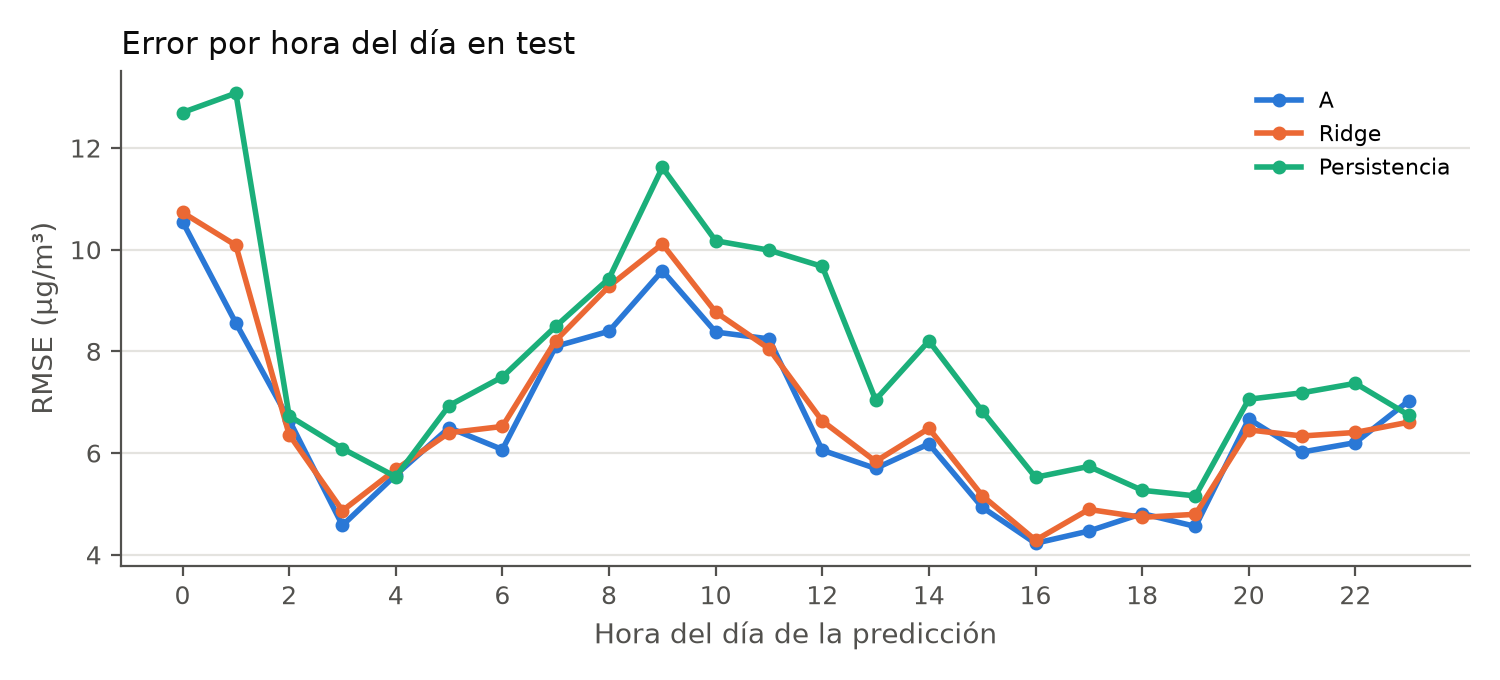

Peores 20 errores de A: 90 % subestimaciones, 90 % en subidas de 5 µg/m³ o más, 90 % con PM2,5 >= 40


,t,y,A,Ridge,ultima_hora,delta
0,2022-12-27 00:00:00,61.4,17.101,18.769,13.1,48.3
1,2022-11-28 10:00:00,71.1,30.444,28.880,34.0,37.1
2,2022-11-28 11:00:00,79.8,41.007,44.951,71.1,8.7
3,2022-11-08 20:00:00,62.2,24.280,26.553,28.8,33.4
4,2022-10-13 01:00:00,55.6,19.636,23.185,19.0,36.6
5,2022-09-21 07:00:00,66.4,33.302,29.999,29.9,36.5
6,2022-10-31 00:00:00,44.9,12.150,13.230,16.0,28.9
7,2022-11-17 08:00:00,71.3,39.076,36.651,38.9,32.4
8,2022-12-27 01:00:00,13.1,45.047,53.560,61.4,-48.3
9,2022-12-07 23:00:00,48.5,19.560,20.951,26.7,21.8


In [17]:
for key, title in (("by_change", "Por tipo de cambio en la hora a predecir"),
                   ("by_imputation", "Por presencia de datos imputados en la ventana"),
                   ("by_month", "Por mes")):
    print(title)
    display(pd.DataFrame({g: {"n": v["A"]["n"], "RMSE A": v["A"]["RMSE"], "Sesgo A": v["A"]["bias"],
                              "RMSE Ridge": v["Ridge"]["RMSE"]} for g, v in fail[key].items()}).T)
display(Image(filename=str(FIGS / "F3_failure_analysis" / "error_by_hour.png"), width=850))
w = fail["worst_20"]
print(f"Peores 20 errores de A: {100*w['share_underestimation']:.0f} % subestimaciones, "
      f"{100*w['share_rises_ge5']:.0f} % en subidas de 5 µg/m³ o más, {100*w['share_y_ge40']:.0f} % con PM2,5 >= 40")
display(pd.DataFrame(w["rows"]).head(10))

**Lectura.**

- **Regresión a la media.** El modelo sobreestima en aire limpio (+3,4 µg/m³ por debajo de 10) y
  subestima los episodios (−14 µg/m³ a partir de 40). Ridge presenta el mismo patrón, lo que sugiere una
  limitación compartida por la información disponible (tres variables de una sola estación) y no
  exclusiva de la STN. La ventaja de A sobre
  Ridge se concentra en niveles bajos y medios; entre 30 y 40 µg/m³ quedan empatados.
- **La falla está en las subidas.** En horas en que el PM2,5 sube 5 µg/m³ o más, el RMSE es 10,5 y el sesgo
  −8,2, frente a 3,9 en horas estables. De los 20 peores errores, el 90 % son subestimaciones en subidas
  hacia episodios de 40 µg/m³ o más, concentrados en la mañana (7–9 h) y cerca de la medianoche, que son
  también las horas de mayor error de todos los modelos.
- **No es un problema de los datos.** La imputación no cambia el error (6,97 frente a 6,78) y el
  desempeño es estable entre septiembre y diciembre.
- **Consecuencia práctica.** El modelo falla al inicio de los episodios, justo cuando una alerta tendría
  valor; usado como alerta temprana subestimaría el riesgo.

### 4.1 Calibración de la confianza

Como el modelo produce un solo número, su confianza se evaluó con intervalos conformales: el ancho del
intervalo es el cuantil del error absoluto en validación, y en test se mide qué fracción de valores reales
cae dentro.

In [18]:
cal = fail["calibration"]
display(pd.DataFrame({nom: {lvl_: v["coverage_mean"] for lvl_, v in by.items()}
                      for nom, by in cal["conformal_coverage_by_level"].items()}).rename_axis("PM2,5 real").add_prefix("nominal "))
print("Cobertura global por semilla:",
      {s: [round(c["coverage_test"], 3) for c in v] for s, v in cal["conformal_per_seed"].items()})
print("Dispersión entre semillas:", {k: (round(v, 3) if isinstance(v, float) else v) for k, v in cal["seed_spread"].items()})

,nominal 0.8,nominal 0.9
"PM2,5 real",,
<10,0.860,0.932
10–20,0.851,0.933
20–30,0.777,0.899
30–40,0.492,0.686
≥40,0.220,0.333


Cobertura global por semilla: {'42': [0.782, 0.874], '123': [0.768, 0.875], '2026': [0.765, 0.872]}
Dispersión entre semillas: {'mean_ug_m3': 0.876, 'corr_spread_vs_abs_error': 0.203, 'mean_abs_error_by_spread_quartile': {'Q1 (menor)': 4.132934207660456, 'Q2': 4.421027167444272, 'Q3': 4.980385269828926, 'Q4 (mayor)': 6.158028047463768}}


**Lectura.** En conjunto, los intervalos cubren casi lo prometido (77–78 % para un 80 % nominal y 87 % para
un 90 %), pero esa cifra esconde el problema: cubren de más en aire limpio y colapsan en los episodios
(22 % y 33 % a partir de 40 µg/m³). El error crece con el nivel y un intervalo de ancho fijo no lo refleja.
La dispersión entre semillas tampoco sirve como medida de confianza: es pequeña (0,9 µg/m³) y casi no se
relaciona con el error (correlación 0,20).

### 4.2 Entradas fuera del dominio de entrenamiento

In [19]:
ood = fail["out_of_domain"]
display(pd.DataFrame({q: {"RMSE A": v["A"]["RMSE"], "RMSE Ridge": v["Ridge"]["RMSE"]}
                      for q, v in ood["error_by_novelty_quartile"].items()}).T.rename_axis("Novedad de la ventana"))
print("Correlación novedad - error absoluto:", round(ood["corr_novelty_vs_abs_error"], 3))
print("Ventanas de test con alguna entrada fuera del rango de train:", ood["test_windows_with_any_input_outside_train_range"])
c = ood["constant_level_inputs"]
display(pd.DataFrame({"Entrada constante (µg/m³)": c["levels_ug_m3"], "Predicción media": c["pred_mean_ug_m3"],
                      **{f"Semilla {s}": v for s, v in c["pred_per_seed"].items()}}).set_index("Entrada constante (µg/m³)"))

,RMSE A,RMSE Ridge
Novedad de la ventana,,
Q1 (más típica),5.462,5.601
Q2,6.570,6.809
Q3,7.295,7.517
Q4 (más novedosa),7.667,8.082


Correlación novedad - error absoluto: 0.142
Ventanas de test con alguna entrada fuera del rango de train: 22


,Predicción media,Semilla 42,Semilla 123,Semilla 2026
Entrada constante (µg/m³),,,,
20.0,20.454,20.704,20.110,20.548
60.0,56.516,54.345,56.514,58.688
80.0,65.569,62.911,65.496,68.300
100.0,69.012,65.516,71.538,69.981
150.0,70.369,64.295,79.393,67.418
200.0,71.455,63.713,87.470,63.182


**Lectura.** El error crece cuando la ventana se parece poco a las de entrenamiento (RMSE 5,5 en el cuartil
más típico frente a 7,7 en el más novedoso), aunque A supera a Ridge en los cuatro cuartiles. El hallazgo
más importante está en los niveles extremos: con 24 horas constantes de 100, 150 o 200 µg/m³, el modelo
predice cerca de 70 y las semillas divergen. **La red se satura hacia 70 µg/m³**; en Fontibón test no hubo
valores tan altos (máximo 79,8), pero un episodio extremo quedaría fuera de su alcance.

## 5. Dictamen sobre la profundidad (8.4)

In [20]:
crit = final["criteria_primera_entrega"]
pd.Series({
    "Reducción consistente del RMSE frente a Ridge (3/3 semillas)": crit["depth_rmse_consistent_vs_ridge"],
    "Mejora en episodios >= 40 µg/m³ (test)": crit["depth_high_episodes_improved_vs_ridge"],
    "Profundidad justificada según la Primera Entrega": crit["depth_justified_by_primera_entrega_criteria"],
    "Transferencia B útil": crit["transfer_B_useful"],
    "Transferencia C útil": crit["transfer_C_useful"],
}, name="Cumple")

Reducción consistente del RMSE frente a Ridge (3/3 semillas)     True
Mejora en episodios >= 40 µg/m³ (test)                           True
Profundidad justificada según la Primera Entrega                 True
Transferencia B útil                                            False
Transferencia C útil                                            False
Name: Cumple, dtype: bool

Con los criterios fijados en la Primera Entrega, ambas condiciones se cumplen, y por eso la arquitectura
profunda queda **justificada, pero por un margen estrecho**. El dictamen completo pondera cuatro elementos:

1. **Comparación.** La mejora frente a Ridge es consistente pero pequeña (0,19 µg/m³, 2,7 %). La mejora en
   episodios altos aparece en test (17,25 frente a 17,87), no en validación (17,88 frente a 17,85), y la
   persistencia es mejor que ambos en los picos (16,66).
2. **Costo.** La STN tiene 99.425 parámetros, tarda entre 2,4 y 3,5 h en entrenar en CPU y unos 14 s en
   predecir el test; Ridge entrena en segundos y predice en 0,002 s.
3. **Datos.** Con unas 10.800 ventanas de entrenamiento, la red no superó de forma apreciable a un modelo
   lineal con la misma información, y la transferencia desde Beijing, pensada para compensar la escasez de
   datos, empeoró el resultado.
4. **Auditoría.** La red aprendió una señal razonable, pero su estrategia es muy cercana a una persistencia
   suavizada, algo que un modelo lineal ya captura.

**Dictamen.** La STN es el mejor modelo en error promedio, pero **no se justifica para el objetivo que
motivó el proyecto**: anticipar mejor los episodios de concentración elevada. Su ventaja es pequeña frente a
su costo, y Ridge sigue siendo una alternativa razonable. La transferencia desde Beijing **no se justifica**.

## 6. Limitaciones y proyección (8.5)

**Limitaciones.**

- **Datos.** Una sola estación y dos años; el test cubre solo septiembre–diciembre de 2022; no hay viento
  comparable entre dominios; la correspondencia del CSV institucional con una fuente pública no pudo
  verificarse.
- **Variable derivada.** El punto de rocío de Fontibón no se midió: se calculó a partir de temperatura y
  humedad relativa con la fórmula de Magnus, lo que agrega el error de ambas mediciones y de la aproximación.
- **Modelo.** STN reducida, sin búsqueda de hiperparámetros, y un solo horizonte (t+1). D no se entrenó por
  completo y B tiene dos semillas (B2026 se interrumpió); ambas son decisiones declaradas.
- **Transferencia.** El supuesto de dinámicas compartidas entre Beijing y Fontibón no se sostuvo.
- **Evaluación.** Tres semillas no permiten inferencia formal y el bootstrap por bloques es descriptivo.
  Los intervalos conformales se calibraron con un período distinto (mayo–septiembre). Los gradientes
  integrados dependen de la línea base elegida, y los casos sintéticos fijan la meteorología en su media.

**Proyección.** Incorporar viento, capa de mezcla y estaciones vecinas; probar pérdidas que castiguen la
subestimación (cuantílica o ponderada por nivel) e intervalos dependientes del nivel; transferir desde
dominios más cercanos, como otras estaciones de Bogotá o ciudades andinas.

**Hacia producción (MLOps).**

- **Versionamiento** de datos, configuraciones, código y checkpoints con SHA-256, como ya se hizo en el
  protocolo de esta fase.
- **Monitoreo** del RMSE y el sesgo móviles por nivel, de la cobertura de los intervalos y de la frecuencia
  de subestimaciones en episodios.
- **Deriva de datos** (cambio en la distribución de las entradas): distancia de las ventanas nuevas al
  entrenamiento, la métrica de novedad ya implementada.
- **Deriva de concepto** (cambio en la relación entre entradas y PM2,5 futuro): error y sesgo móviles que
  empeoran aunque las entradas sigan dentro del rango de entrenamiento.
- **Esquema del pipeline:** ingesta horaria → validación de datos → ventanas y escalado versionado →
  predicción → registro del valor real → monitoreo → alertas, respaldo y reentrenamiento.
- **Salvaguardas:** una alerta cuando la entrada supere el rango de entrenamiento, dado que el modelo se
  satura cerca de 70 µg/m³, y un modelo de respaldo como la persistencia o Ridge.
- **Reentrenamiento** periódico, validado siempre con una partición cronológica.

## 7. Pruebas de software

`tests/test_f3_audit.py` agrega pruebas para las piezas nuevas:
- la extracción de atención reproduce el forward del modelo;
- los pesos tienen la forma esperada, son finitos y están normalizados;
- el protocolo fija el modelo A y el umbral de 40;
- la evaluación final fue solo inferencia, sobre 2.574 ventanas;
- las predicciones y Ridge comparten fechas y valores reales.

La celda siguiente lee la última ejecución real de `pytest tests/ -v`, guardada en
`outputs/pytest_fase3_full.txt`.

In [21]:
log = (OUTPUTS_DIR / "pytest_fase3_full.txt").read_text(encoding="utf-8", errors="replace").splitlines()
print(next((l for l in reversed(log) if " passed" in l or " failed" in l), "sin resumen"))
print("\n".join(l for l in log if "test_f3_audit.py" in l and "::" in l))

=============== 209 passed, 1142 warnings in 427.47s (0:07:07) ================
tests/test_f3_audit.py::test_forward_with_attention_reproduces_model_forward PASSED [ 21%]
tests/test_f3_audit.py::test_attention_shapes_finite_and_normalized PASSED [ 21%]
tests/test_f3_audit.py::test_frozen_protocol_final_model_and_threshold PASSED [ 22%]
tests/test_f3_audit.py::test_final_evaluation_was_inference_only PASSED  [ 22%]
tests/test_f3_audit.py::test_predictions_timestamps_and_targets_match_ridge PASSED [ 22%]
tests/test_f3_audit.py::test_high_episode_count_uses_threshold_40 PASSED [ 23%]
tests/test_f3_audit.py::test_attention_audit_used_real_weights_of_final_model PASSED [ 23%]
tests/test_f3_audit.py::test_fontibon_test_has_2574_windows PASSED       [ 24%]


## Reproducibilidad y uso de IA

Los resultados de este notebook se regeneran ejecutando los cinco scripts de la Fase 3 en orden (protocolo, test, explicabilidad, matrices de atención y fallas), con el
entorno de `requirements.txt` (TensorFlow 2.21, Keras 3.15). La evaluación de test no se puede repetir: el
script se niega a sobrescribir `F3_test_final_summary.json`. La explicabilidad se ejecutó dos veces y produjo
resultados idénticos.

Se usaron herramientas de IA generativa como apoyo en la programación de los scripts de auditoría, la
organización de resultados y la redacción. Las cifras provienen de los archivos de resultados obtenidos al
ejecutar los experimentos; las decisiones metodológicas fueron revisadas por el autor, quien debe poder
sustentarlas.